# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [3]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\04. Calculus 1 Extra Practice with Integrals - Vol 2'

In [4]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [5]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 07. Calculating Volume with the Washer Method, Part 1


<img src="./pics/Fig07_01.png" width=600> 


<img src="./pics/Fig07_02.png" width=500> 


### Exercise 1
Volume using washer method

$$f(x) = \sqrt{x+1}   \quad g(x) = \sqrt{x-1} \quad ; \quad [1, 3]$$

In [13]:
# washer method
f = sp.sqrt(x + 1)
g = sp.sqrt(x - 1)

V = sp.Integral(sp.pi * ((f) ** 2 - (g) ** 2), (x, 1, 3))
answer = V.doit().factor()
display(Math(rf"f(x) = {sp.latex(f)}"))
display(Math(rf"g(x) = {sp.latex(g)}"))
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

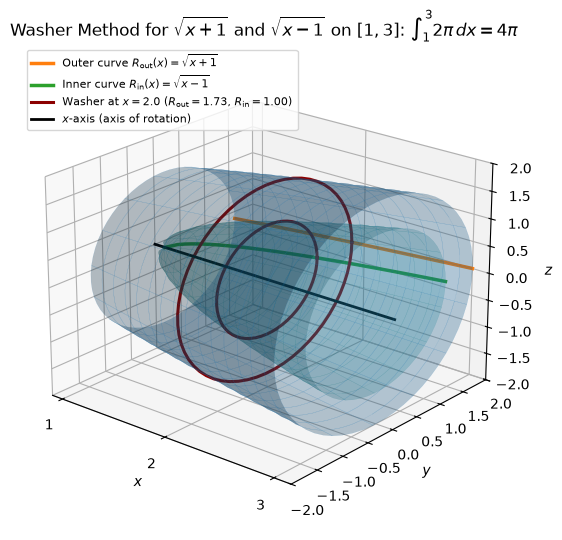

In [ ]:
# Symbolic outer radius f(x) = sqrt(x + 1) and inner radius g(x) = sqrt(x - 1) on [1, 3]
x = sp.Symbol("x", real=True)
f_sym = sp.sqrt(x + 1)
g_sym = sp.sqrt(x - 1)

f_num = sp.lambdify(x, f_sym, "numpy")
g_num = sp.lambdify(x, g_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [1, 3], theta in [0, 2*pi]
x_vals = np.linspace(1.0, 3.0, 60)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

R_out = f_num(X)
R_in = g_num(X)

# Outer surface coordinates
Y_out = R_out * np.cos(THETA)
Z_out = R_out * np.sin(THETA)

# Inner hollow bore surface coordinates
Y_in = R_in * np.cos(THETA)
Z_in = R_in * np.sin(THETA)

r_max = float(np.max(R_out))
bound = np.ceil(r_max * 10) / 10.0

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot outer surface and inner hollow bore
ax.plot_surface(
    X,
    Y_out,
    Z_out,
    color="tab:blue",
    alpha=0.30,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)
ax.plot_surface(
    X,
    Y_in,
    Z_in,
    color="tab:cyan",
    alpha=0.22,
    edgecolor="teal",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight outer and inner generating curves in the x-y plane (z = 0)
ax.plot(
    x_vals,
    f_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Outer curve $R_{\mathrm{out}}(x) = \sqrt{x+1}$",
)
ax.plot(
    x_vals,
    g_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:green",
    linewidth=2.5,
    label=r"Inner curve $R_{\mathrm{in}}(x) = \sqrt{x-1}$",
)

# Highlight a representative washer slice (outer + inner rings) at x = 2.0
x_washer = 2.0
r_o = float(f_num(x_washer))
r_i = float(g_num(x_washer))

ax.plot(
    np.full_like(theta_vals, x_washer),
    r_o * np.cos(theta_vals),
    r_o * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Washer at $x = {x_washer:.1f}$ ($R_{{\mathrm{{out}}}} = {r_o:.2f}$, $R_{{\mathrm{{in}}}} = {r_i:.2f}$)",
)
ax.plot(
    np.full_like(theta_vals, x_washer),
    r_i * np.cos(theta_vals),
    r_i * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
)

# Axis of revolution (x-axis)
ax.plot(
    [0.9, 3.15],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(0.9, 3.15)
ax.set_ylim(-bound, bound)
ax.set_zlim(-bound, bound)
ax.set_xticks([1.0, 2.0, 3.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Washer Method for $\sqrt{x+1}$ and $\sqrt{x-1}$ on $[1, 3]$:"
    r" $\int_{1}^{3} 2\pi\,dx = 4\pi$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

### Exercise 2
Volume using washer method

$$f(x) = \cos x + \sin x   \quad g(x) = \cos x - \sin x   \quad ; \quad [0, \frac{\pi}{4}] $$

In [ ]:
# washer method
f = sp.cos(x) + sp.sin(x)
g = sp.cos(x) - sp.sin(x)

V = sp.Integral(sp.pi * ((f) ** 2 - (g) ** 2), (x, 0, sp.pi / 4))
answer = V.doit()
display(Math(rf"f(x) = {sp.latex(f)}"))
display(Math(rf"g(x) = {sp.latex(g)}"))
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

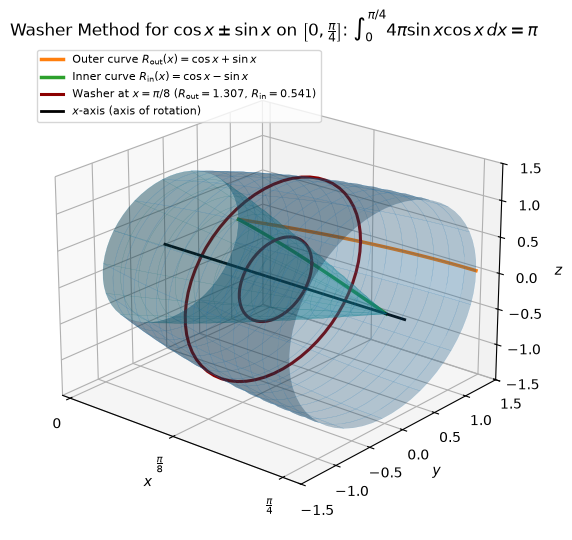

In [17]:
# Symbolic outer and inner radii on [0, pi/4]
x = sp.Symbol("x", real=True)
f_sym = sp.cos(x) + sp.sin(x)
g_sym = sp.cos(x) - sp.sin(x)

f_num = sp.lambdify(x, f_sym, "numpy")
g_num = sp.lambdify(x, g_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [0, pi/4], theta in [0, 2*pi]
x_vals = np.linspace(0.0, np.pi / 4.0, 60)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

R_out = f_num(X)
R_in = g_num(X)

Y_out = R_out * np.cos(THETA)
Z_out = R_out * np.sin(THETA)

Y_in = R_in * np.cos(THETA)
Z_in = R_in * np.sin(THETA)

r_max = float(np.max(R_out))
bound = np.ceil(r_max * 10) / 10.0

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot outer surface and inner hollow bore using valid Matplotlib colors
ax.plot_surface(
    X,
    Y_out,
    Z_out,
    color="tab:blue",
    alpha=0.30,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)
ax.plot_surface(
    X,
    Y_in,
    Z_in,
    color="tab:cyan",
    alpha=0.22,
    edgecolor="darkcyan",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight outer and inner generating curves in the x-y plane (z = 0)
ax.plot(
    x_vals,
    f_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Outer curve $R_{\mathrm{out}}(x) = \cos x + \sin x$",
)
ax.plot(
    x_vals,
    g_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:green",
    linewidth=2.5,
    label=r"Inner curve $R_{\mathrm{in}}(x) = \cos x - \sin x$",
)

# Highlight a representative washer slice at x = pi/8
x_washer = np.pi / 8.0
r_o = float(f_num(x_washer))
r_i = float(g_num(x_washer))

ax.plot(
    np.full_like(theta_vals, x_washer),
    r_o * np.cos(theta_vals),
    r_o * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Washer at $x = \pi/8$ ($R_{{\mathrm{{out}}}} = {r_o:.3f}$, $R_{{\mathrm{{in}}}} = {r_i:.3f}$)",
)
ax.plot(
    np.full_like(theta_vals, x_washer),
    r_i * np.cos(theta_vals),
    r_i * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
)

# Axis of revolution (x-axis)
ax.plot(
    [-0.03, np.pi / 4.0 * 1.08],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(-0.03, np.pi / 4.0 * 1.08)
ax.set_ylim(-bound, bound)
ax.set_zlim(-bound, bound)
ax.set_xticks([0.0, np.pi / 8.0, np.pi / 4.0])
ax.set_xticklabels([r"$0$", r"$\frac{\pi}{8}$", r"$\frac{\pi}{4}$"])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Washer Method for $\cos x \pm \sin x$ on $\left[0, \frac{\pi}{4}\right]$:"
    r" $\int_{0}^{\pi/4} 4\pi\sin x\cos x\,dx = \pi$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()